In [1]:
import numpy as np
import matplotlib
from matplotlib import pyplot as plot
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
import sklearn.metrics
from sklearn.metrics import explained_variance_score, mean_squared_error, r2_score # https://scikit-learn.org/stable/auto_examples/linear_model/plot_ols.html
import statsmodels.api as sm
import pandas
import matplotlib.pyplot as plt
import scipy as sp
from scipy.odr import *
import random

# For 3d plots. This import is necessary to have 3D plotting below
from mpl_toolkits.mplot3d import Axes3D

# For statistics. Requires statsmodels 5.0 or more
from statsmodels.formula.api import ols
from statsmodels.formula.api import wls
# Analysis of Variance (ANOVA) on linear models
from statsmodels.stats.anova import anova_lm

# Adapted from:
# https://www.datasciencecentral.com/profiles/blogs/linear-regression-in-python-use-of-numpy-scipy-and-statsmodels,
# https://realpython.com/linear-regression-in-python/#multiple-linear-regression

This is a simple formula analysis of the 8 equations we have found. The goal is simply to see how well the corresponding Q and Qx permutations compare with each other. Ideally, there should be little difference in which choice we make between Q and Qx.

# Stellar relations (RLM and MLP)
## M0
logR(logL, logP) = 0.289 + 0.417 logL + 0.195 logP

logM(logL, logP) = -2.112 + 1.085 logL - 0.776 logP

=> logP (logL, logM) = -2.722 + 1.398 logL - 1.289 logM

## M1
logR(logL, logP) = 0.284 + 0.395 logL + 0.272 logP

logM(logL, logP) = -2.093 + 1.174 logL - 1.083 logP

=> logP (logL, logM) = -1.933 + 1.084 logL - 0.923 logM

## C0
logR(logL, logP) = 0.367 + 0.384 logL + 0.234 logP

logM(logL, logP) = -1.859 + 0.951 logL - 0.631 logP

=> logP (logL, logM) = -2.946 + 1.507 logL - 1.585 logM
logP0 = -2.285(7) - 0.826(4)logM + 2.043(3)logR
## C1
logR(logL, logP) = 0.365 + 0.351 logL + 0.334 logP

logM(logL, logP) = -1.854 + 1.041 logL - 0.900 logP

=> logP (logL, logM) = -2.060 + 1.157 logL - 1.111 logM

# Grouping by Method
## Q
### M
#### Fundamental
NewMdotCalc = 8.910337063166505 + 14.204958005165299 log(P/L^W) +  7.478280898278678 logM -  5.8076081856640105 logP ; W = 0.6826765393688697
NewMdotCalc = 8.910337063166505 + ( 8.397349819501288 ) logP + ( -9.697391572846369 ) logL +  7.478280898278678 logM

M0: NewMdotCalc = 8.910337063166505 + 14.204958005165299 log(P/L^W) +  7.478280898278678 logM -  5.8076081856640105 logP ; W = 0.6826765393688697



=> logMdot = 8.910337063166505 + ( 8.397349819501288 ) logP + ( -9.697391572846369 ) logL +  7.478280898278678 logM
#### Overtone
M1: NewMdotCalc = 2.2239173678372657 + 14.551346249573244 log(P/L^W) +  4.1071270378651725 logM -  2.856887752620167 logP ; W = 0.61144119885264

=> logMdot = 2.2239173678372657 + ( 11.694458496953077 ) logP + ( -8.897292595758932 ) logL +  4.1071270378651725 logM
### C
#### Fundamental
C0: NewMdotCalc = -5.95866305105158 + 9.571964457927034 log(P/L^W) +  2.4178993691909967 logM -  3.8971993666460527 logP ; W = 0.41870953488462537

=> logMdot = -5.95866305105158 + ( 5.674765091280982 ) logP + ( -4.007872786110794 ) logL +  2.4178993691909967 logM
#### Overtone
C1: NewMdotCalc = -6.164203073186435 + 7.142007659021788 log(P/L^W) +  2.4036829249153104 logM -  2.955133277926976 logP ; W = 0.37085618916281626

=> logMdot =  -6.164203073186435 + ( 4.186874381094812 ) logP + ( -2.6486577433964666 ) logL +  2.4036829249153104 logM

## Qx
### M
#### Fundamental
M0: NewMdotCalc = 10.717445131185093 + 14.882510709730816 log(P/L^W) +  8.317911215185012 logM -  5.8107086864723785 logP ; W = 0.7144105224788051

=> logMdot =  10.717445131185093 + ( 9.071802023258439 ) logP + ( -10.632222251935206 ) logL +  8.317911215185012 logM
#### Overtone
M1: NewMdotCalc = 0.3847160476550018 + 13.632467686506367 log(P/L^W) +  3.2055729270070246 logM -  2.841636179438342 logP ; W = 0.5789290657947175

=> logMdot =  0.3847160476550018 + ( 10.790831507068024 ) logP + ( -7.892231782225804 ) logL +  3.2055729270070246 logM
### C
#### Fundamental
C0: NewMdotCalc = -3.9054394861032105 + 10.293310343958131 log(P/L^W) +  3.579255830706669 logM -  3.979378308217936 logP ; W = 0.48793438880082113

=> logMdot =  -3.9054394861032105 + ( 6.313932035740195 ) logP + ( -5.022460091416381 ) logL +  3.579255830706669 logM
#### Overtone
C1: NewMdotCalc = -4.006544049178007 + 8.222458126270334 log(P/L^W) +  3.595863233190134 logM -  2.9971425862680166 logP ; W = 0.46898473968773413

=> logMdot =  -4.006544049178007 + ( 5.225315540002318 ) logP + ( -3.856207383942187 ) logL +  3.595863233190134 logM

# Grouping by Star
## M
### Fundamental
#### Q
logMdot = 8.910337063166505 + ( 8.397349819501288 ) logP + ( -9.697391572846369 ) logL +  7.478280898278678 logM
#### Qx
logMdot =  10.717445131185093 + ( 9.071802023258439 ) logP + ( -10.632222251935206 ) logL +  8.317911215185012 logM
## M
### Overtone
#### Q
logMdot = 2.2239173678372657 + ( 11.694458496953077 ) logP + ( -8.897292595758932 ) logL +  4.1071270378651725 logM
#### Qx
logMdot =  0.3847160476550018 + ( 10.790831507068024 ) logP + ( -7.892231782225804 ) logL +  3.2055729270070246 logM
## C
### Fundamental
#### Q
logMdot = -5.95866305105158 + ( 5.674765091280982 ) logP + ( -4.007872786110794 ) logL +  2.4178993691909967 logM
#### Qx
logMdot =  -3.9054394861032105 + ( 6.313932035740195 ) logP + ( -5.022460091416381 ) logL +  3.579255830706669 logM
## C
### Overtone
#### Q
logMdot =  -6.164203073186435 + ( 4.186874381094812 ) logP + ( -2.6486577433964666 ) logL +  2.4036829249153104 logM
#### Qx
logMdot =  -4.006544049178007 + ( 5.225315540002318 ) logP + ( -3.856207383942187 ) logL +  3.595863233190134 logM

In [85]:
def logMdot_M_0_Q (logL, logM):
    logMdotArray = [] # Empty List
    logPArray = []
    logRArray = []
    for i in range(0,len(logM)):
        logMdotRow = [] # Clear and initialize
        logPRow = [] # Clear and initialize
        logRRow = [] # Clear and initialize
        for j in range(0,len(logL)):
            # logP (logL, logM) = -2.722 + 1.398 logL - 1.289 logM
            logP = -2.722 + 1.398*logL[j] - 1.289*logM[i]
            # logR(logL, logP) = 0.289 + 0.417 logL + 0.195 logP
            logR = 0.289 + 0.416*logL[j] + 0.195*logP
            # logMdot = 8.910337063166505 + ( 8.397349819501288 ) logP + ( -9.697391572846369 ) logL + 7.478280898278678 logM
            logMdot = 8.910 + 8.397*logP + (-9.697)*logL[j] + 7.478*logM[i]
            logMdotRow.append(logMdot)
            logPRow.append(logP)
            logRRow.append(logR)
        logMdotArray.append(logMdotRow)
        logPArray.append(logPRow)
        logRArray.append(logRRow)
    return np.asarray(logMdotArray), np.asarray(logPArray), np.asarray(logRArray)

def logMdot_M_0_Qx (logL, logM):
    logMdotArray = [] # Empty List
    logPArray = []
    logRArray = []
    for i in range(0,len(logM)):
        logMdotRow = [] # Clear and initialize
        logPRow = [] # Clear and initialize
        logRRow = [] # Clear and initialize
        for j in range(0,len(logL)):
            # logP (logL, logM) = -2.722 + 1.398 logL - 1.289 logM
            logP = -2.722 + 1.398*logL[j] - 1.289*logM[i]
            # logR(logL, logP) = 0.289 + 0.417 logL + 0.195 logP
            logR = 0.289 + 0.416*logL[j] + 0.195*logP
            # logMdot = 10.717445131185093 + ( 9.071802023258439 ) logP + ( -10.632222251935206 ) logL + 8.317911215185012 logM
            logMdot = 10.717 + 9.072*logP + (-10.632)*logL[j] + 8.318*logM[i]
            logMdotRow.append(logMdot)
            logPRow.append(logP)
            logRRow.append(logR)
        logMdotArray.append(logMdotRow)
        logPArray.append(logPRow)
        logRArray.append(logRRow)
    return np.asarray(logMdotArray), np.asarray(logPArray), np.asarray(logRArray)

def logMdot_M_1_Q (logL, logM):
    logMdotArray = [] # Empty List
    logPArray = []
    logRArray = []
    for i in range(0,len(logM)):
        logMdotRow = [] # Clear and initialize
        logPRow = [] # Clear and initialize
        logRRow = [] # Clear and initialize
        for j in range(0,len(logL)):
            # logP (logL, logM) = -1.933 + 1.084 logL - 0.923 logM
            logP = -1.933 + 1.084*logL[j] - 0.923*logM[i]
            # logR(logL, logP) = 0.284 + 0.395 logL + 0.272 logP
            logR = 0.284 + 0.395*logL[j] + 0.272*logP
            # logMdot = 2.2239173678372657 + ( 11.694458496953077 ) logP + ( -8.897292595758932 ) logL + 4.1071270378651725 logM
            logMdot = 2.224 + 11.694*logP + (-8.897)*logL[j] + 4.107*logM[i]
            logMdotRow.append(logMdot)
            logPRow.append(logP)
            logRRow.append(logR)
        logMdotArray.append(logMdotRow)
        logPArray.append(logPRow)
        logRArray.append(logRRow)
    return np.asarray(logMdotArray), np.asarray(logPArray), np.asarray(logRArray)

def logMdot_M_1_Qx (logL, logM):
    logMdotArray = [] # Empty List
    logPArray = []
    logRArray = []
    for i in range(0,len(logM)):
        logMdotRow = [] # Clear and initialize
        logPRow = [] # Clear and initialize
        logRRow = [] # Clear and initialize
        for j in range(0,len(logL)):
            # logP (logL, logM) = -1.933 + 1.084 logL - 0.923 logM
            logP = -1.933 + 1.084*logL[j] - 0.923*logM[i]
            # logR(logL, logP) = 0.284 + 0.395 logL + 0.272 logP
            logR = 0.284 + 0.395*logL[j] + 0.272*logP
            # logMdot = 0.3847160476550018 + ( 10.790831507068024 ) logP + ( -7.892231782225804 ) logL + 3.2055729270070246 logM
            logMdot = 0.385 + 10.791*logP + (-7.892)*logL[j] + 3.206*logM[i]
            logMdotRow.append(logMdot)
            logPRow.append(logP)
            logRRow.append(logR)
        logMdotArray.append(logMdotRow)
        logPArray.append(logPRow)
        logRArray.append(logRRow)
    return np.asarray(logMdotArray), np.asarray(logPArray), np.asarray(logRArray)

def logMdot_C_0_Q (logL, logM):
    logMdotArray = [] # Empty List
    logPArray = []
    logRArray = []
    for i in range(0,len(logM)):
        logMdotRow = [] # Clear and initialize
        logPRow = [] # Clear and initialize
        logRRow = [] # Clear and initialize
        for j in range(0,len(logL)):
            # logP (logL, logM) = -2.946 + 1.507 logL - 1.585 logM
            logP = -2.946 + 1.507*logL[j] - 1.585*logM[i]
            # logR(logL, logP) = 0.367 + 0.384 logL + 0.234 logP
            logR = 0.367 + 0.384*logL[j] + 0.234*logP
            # logMdot = -5.95866305105158 + ( 5.674765091280982 ) logP + ( -4.007872786110794 ) logL + 2.4178993691909967 logM
            logMdot = -5.959 + 5.675*logP + (-4.008)*logL[j] + 2.418*logM[i]
            logMdotRow.append(logMdot)
            logPRow.append(logP)
            logRRow.append(logR)
        logMdotArray.append(logMdotRow)
        logPArray.append(logPRow)
        logRArray.append(logRRow)
    return np.asarray(logMdotArray), np.asarray(logPArray), np.asarray(logRArray)

def logMdot_C_0_Qx (logL, logM):
    logMdotArray = [] # Empty List
    logPArray = []
    logRArray = []
    for i in range(0,len(logM)):
        logMdotRow = [] # Clear and initialize
        logPRow = [] # Clear and initialize
        logRRow = [] # Clear and initialize
        for j in range(0,len(logL)):
            # logP (logL, logM) = -2.946 + 1.507 logL - 1.585 logM
            logP = -2.946 + 1.507*logL[j] - 1.585*logM[i]
            # logR(logL, logP) = 0.367 + 0.384 logL + 0.234 logP
            logR = 0.367 + 0.384*logL[j] + 0.234*logP
            # logMdot = -3.9054394861032105 + ( 6.313932035740195 ) logP + ( -5.022460091416381 ) logL + 3.579255830706669 logM
            logMdot = -3.905 + 6.314*logP + (-5.022)*logL[j] + 3.579*logM[i]
            logMdotRow.append(logMdot)
            logPRow.append(logP)
            logRRow.append(logR)
        logMdotArray.append(logMdotRow)
        logPArray.append(logPRow)
        logRArray.append(logRRow)
    return np.asarray(logMdotArray), np.asarray(logPArray), np.asarray(logRArray)

def logMdot_C_1_Q (logL, logM):
    logMdotArray = [] # Empty List
    logPArray = []
    logRArray = []
    for i in range(0,len(logM)):
        logMdotRow = [] # Clear and initialize
        logPRow = [] # Clear and initialize
        logRRow = [] # Clear and initialize
        for j in range(0,len(logL)):
            # logP (logL, logM) = -2.060 + 1.157 logL - 1.111 logM
            logP = -2.060 + 1.157*logL[j] - 1.111*logM[i]
            # logR(logL, logP) = 0.365 + 0.351 logL + 0.334 logP
            logR = 0.365 + 0.351*logL[j] + 0.334*logP
            # logMdot = -6.164203073186435 + ( 4.186874381094812 ) logP + ( -2.6486577433964666 ) logL + 2.4036829249153104 logM
            logMdot = -6.164 + 4.186*logP + (-2.649)*logL[j] + 2.404*logM[i]
            logMdotRow.append(logMdot)
            logPRow.append(logP)
            logRRow.append(logR)
        logMdotArray.append(logMdotRow)
        logPArray.append(logPRow)
        logRArray.append(logRRow)
    return np.asarray(logMdotArray), np.asarray(logPArray), np.asarray(logRArray)

def logMdot_C_1_Qx (logL, logM):
    logMdotArray = [] # Empty List
    logPArray = []
    logRArray = []
    for i in range(0,len(logM)):
        logMdotRow = [] # Clear and initialize
        logPRow = [] # Clear and initialize
        logRRow = [] # Clear and initialize
        for j in range(0,len(logL)):
            # logP (logL, logM) = -2.060 + 1.157 logL - 1.111 logM
            logP = -2.060 + 1.157*logL[j] - 1.111*logM[i]
            # logR(logL, logP) = 0.365 + 0.351 logL + 0.334 logP
            logR = 0.365 + 0.351*logL[j] + 0.334*logP
            # logMdot = -4.006544049178007 + ( 5.225315540002318 ) logP + ( -3.856207383942187 ) logL + 3.595863233190134 logM
            logMdot = -4.006 + 5.225*logP + (-3.856)*logL[j] + 3.596*logM[i]
            logMdotRow.append(logMdot)
            logPRow.append(logP)
            logRRow.append(logR)
        logMdotArray.append(logMdotRow)
        logPArray.append(logPRow)
        logRArray.append(logRRow)
    return np.asarray(logMdotArray), np.asarray(logPArray), np.asarray(logRArray)


In [86]:
MassArray = np.log10(np.asarray([0.8,1.0,1.2,1.5]))
LuminosityArray = np.arange(3,4.2,0.1)

In [87]:
LuminosityArray

array([3. , 3.1, 3.2, 3.3, 3.4, 3.5, 3.6, 3.7, 3.8, 3.9, 4. , 4.1, 4.2])

In [90]:
logMdotM0Q, logPM0, logRM0 = logMdot_M_0_Q (LuminosityArray, MassArray)
logMdotM0Qx, logPM0, logRM0 = logMdot_M_0_Qx (LuminosityArray, MassArray)
logMdotM1Q, logPM1, logRM1 = logMdot_M_1_Q (LuminosityArray, MassArray)
logMdotM1Qx, logPM1, logRM1 = logMdot_M_1_Qx (LuminosityArray, MassArray)
logMdotC0Q, logPC0, logRC0 = logMdot_C_0_Q (LuminosityArray, MassArray)
logMdotC0Qx, logPC0, logRC0 = logMdot_C_0_Qx (LuminosityArray, MassArray)
logMdotC1Q, logPC1, logRC1 = logMdot_C_1_Q (LuminosityArray, MassArray)
logMdotC1Qx, logPC1, logRC1 = logMdot_C_1_Qx (LuminosityArray, MassArray)

delta_log_Mdot_M0 = logMdotM0Q - logMdotM0Qx
delta_log_Mdot_M1 = logMdotM1Q - logMdotM1Qx
delta_log_Mdot_C0 = logMdotC0Q - logMdotC0Qx
delta_log_Mdot_C1 = logMdotC1Q - logMdotC1Qx

Text(0.5, 1.0, 'Mdot vs L; Q,\n (blue = 0.7, green = 1, red = 1.2, black = 1.5 solar masses) \n (circle = M0, Triangle = M1, Diamond = C0, Square = C1)')

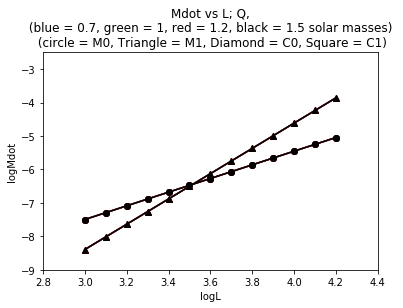

In [103]:
plot.plot(LuminosityArray,logMdotM0Q[0],color='b',marker='o')
plot.plot(LuminosityArray,logMdotM1Q[0],color='b',marker='^')
plot.plot(LuminosityArray,logMdotM0Q[0],color='g',marker='o')
plot.plot(LuminosityArray,logMdotM1Q[0],color='g',marker='^')
plot.plot(LuminosityArray,logMdotM0Q[0],color='r',marker='o')
plot.plot(LuminosityArray,logMdotM1Q[0],color='r',marker='^')
plot.plot(LuminosityArray,logMdotM0Q[0],color='k',marker='o')
plot.plot(LuminosityArray,logMdotM1Q[0],color='k',marker='^')

plot.xlabel('logL')
plot.ylabel('logMdot')
plot.xlim(2.8,4.4)
plot.ylim(-9,-2.5)
plot.title('Mdot vs L; Q,\n (blue = 0.7, green = 1, red = 1.2, black = 1.5 solar masses) \n (circle = M0, Triangle = M1, Diamond = C0, Square = C1)')

Text(0.5, 1.0, 'Mdot vs L; Qx,\n (blue = 0.7, green = 1, red = 1.2, black = 1.5 solar masses) \n (circle = M0, Triangle = M1, Diamond = C0, Square = C1)')

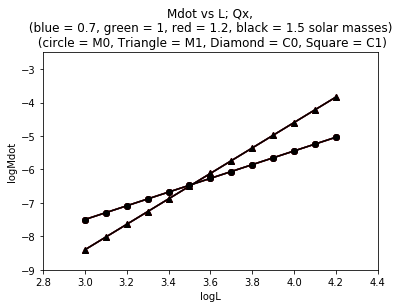

In [104]:
plot.plot(LuminosityArray,logMdotM0Qx[0],color='b',marker='o')
plot.plot(LuminosityArray,logMdotM1Qx[0],color='b',marker='^')
plot.plot(LuminosityArray,logMdotM0Qx[0],color='g',marker='o')
plot.plot(LuminosityArray,logMdotM1Qx[0],color='g',marker='^')
plot.plot(LuminosityArray,logMdotM0Qx[0],color='r',marker='o')
plot.plot(LuminosityArray,logMdotM1Qx[0],color='r',marker='^')
plot.plot(LuminosityArray,logMdotM0Qx[0],color='k',marker='o')
plot.plot(LuminosityArray,logMdotM1Qx[0],color='k',marker='^')

plot.xlabel('logL')
plot.ylabel('logMdot')
plot.xlim(2.8,4.4)
plot.ylim(-9,-2.5)
plot.title('Mdot vs L; Qx,\n (blue = 0.7, green = 1, red = 1.2, black = 1.5 solar masses) \n (circle = M0, Triangle = M1, Diamond = C0, Square = C1)')

Text(0.5, 1.0, 'Mdot vs L; Q,\n (blue = 0.7, green = 1, red = 1.2, black = 1.5 solar masses) \n (circle = M0, Triangle = M1, Diamond = C0, Square = C1)')

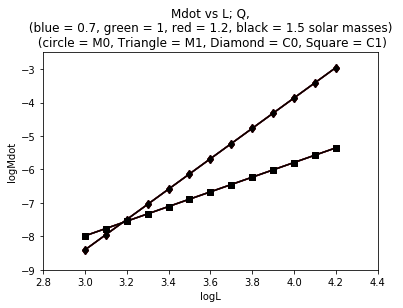

In [106]:
plot.plot(LuminosityArray,logMdotC0Q[0],color='b',marker='d')
plot.plot(LuminosityArray,logMdotC1Q[0],color='b',marker='s')
plot.plot(LuminosityArray,logMdotC0Q[0],color='g',marker='d')
plot.plot(LuminosityArray,logMdotC1Q[0],color='g',marker='s')
plot.plot(LuminosityArray,logMdotC0Q[0],color='r',marker='d')
plot.plot(LuminosityArray,logMdotC1Q[0],color='r',marker='s')
plot.plot(LuminosityArray,logMdotC0Q[0],color='k',marker='d')
plot.plot(LuminosityArray,logMdotC1Q[0],color='k',marker='s')

plot.xlabel('logL')
plot.ylabel('logMdot')
plot.xlim(2.8,4.4)
plot.ylim(-9,-2.5)
plot.title('Mdot vs L; Q,\n (blue = 0.7, green = 1, red = 1.2, black = 1.5 solar masses) \n (circle = M0, Triangle = M1, Diamond = C0, Square = C1)')

Text(0.5, 1.0, 'Mdot vs L; Qx,\n (blue = 0.7, green = 1, red = 1.2, black = 1.5 solar masses) \n (circle = M0, Triangle = M1, Diamond = C0, Square = C1)')

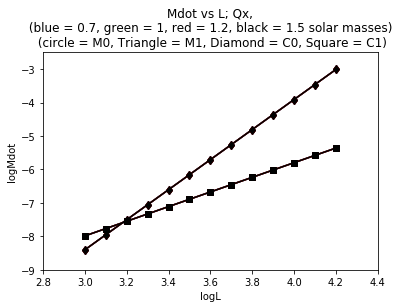

In [105]:
plot.plot(LuminosityArray,logMdotC0Qx[0],color='b',marker='d')
plot.plot(LuminosityArray,logMdotC1Qx[0],color='b',marker='s')
plot.plot(LuminosityArray,logMdotC0Qx[0],color='g',marker='d')
plot.plot(LuminosityArray,logMdotC1Qx[0],color='g',marker='s')
plot.plot(LuminosityArray,logMdotC0Qx[0],color='r',marker='d')
plot.plot(LuminosityArray,logMdotC1Qx[0],color='r',marker='s')
plot.plot(LuminosityArray,logMdotC0Qx[0],color='k',marker='d')
plot.plot(LuminosityArray,logMdotC1Qx[0],color='k',marker='s')

plot.xlabel('logL')
plot.ylabel('logMdot')
plot.xlim(2.8,4.4)
plot.ylim(-9,-2.5)
plot.title('Mdot vs L; Qx,\n (blue = 0.7, green = 1, red = 1.2, black = 1.5 solar masses) \n (circle = M0, Triangle = M1, Diamond = C0, Square = C1)')

Text(0.5, 1.0, 'Mdot vs L,\n (blue = 0.7, green = 1, red = 1.2, black = 1.5 solar masses) \n (circle = M0, Triangle = M1, Diamond = C0, Square = C1)')

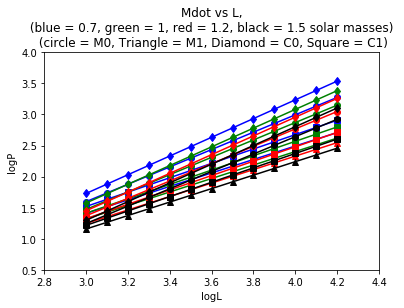

In [107]:
plot.plot(LuminosityArray,logPM0[0],color='b',marker='o')
plot.plot(LuminosityArray,logPM1[0],color='b',marker='^')
plot.plot(LuminosityArray,logPC0[0],color='b',marker='d')
plot.plot(LuminosityArray,logPC1[0],color='b',marker='s')

plot.plot(LuminosityArray,logPM0[1],color='g',marker='o')
plot.plot(LuminosityArray,logPM1[1],color='g',marker='^')
plot.plot(LuminosityArray,logPC0[1],color='g',marker='d')
plot.plot(LuminosityArray,logPC1[1],color='g',marker='s')

plot.plot(LuminosityArray,logPM0[2],color='r',marker='o')
plot.plot(LuminosityArray,logPM1[2],color='r',marker='^')
plot.plot(LuminosityArray,logPC0[2],color='r',marker='d')
plot.plot(LuminosityArray,logPC1[2],color='r',marker='s')

plot.plot(LuminosityArray,logPM0[3],color='k',marker='o')
plot.plot(LuminosityArray,logPM1[3],color='k',marker='^')
plot.plot(LuminosityArray,logPC0[3],color='k',marker='d')
plot.plot(LuminosityArray,logPC1[3],color='k',marker='s')

plot.xlabel('logL')
plot.ylabel('logP')
plot.xlim(2.8,4.4)
plot.ylim(0.5,4)
plot.title('Mdot vs L,\n (blue = 0.7, green = 1, red = 1.2, black = 1.5 solar masses) \n (circle = M0, Triangle = M1, Diamond = C0, Square = C1)')

Text(0.5, 1.0, 'R vs L,\n (blue = 0.7, green = 1, red = 1.2, black = 1.5 solar masses) \n (circle = M0, Triangle = M1, Diamond = C0, Square = C1)')

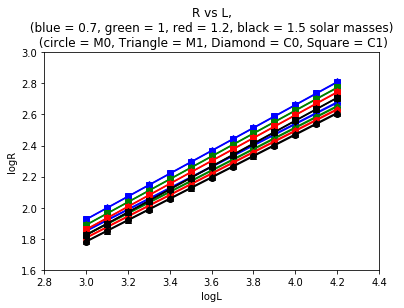

In [108]:
plot.plot(LuminosityArray,logRM0[0],color='b',marker='o')
plot.plot(LuminosityArray,logRM1[0],color='b',marker='^')
plot.plot(LuminosityArray,logRC0[0],color='b',marker='d')
plot.plot(LuminosityArray,logRC1[0],color='b',marker='s')

plot.plot(LuminosityArray,logRM0[1],color='g',marker='o')
plot.plot(LuminosityArray,logRM1[1],color='g',marker='^')
plot.plot(LuminosityArray,logRC0[1],color='g',marker='d')
plot.plot(LuminosityArray,logRC1[1],color='g',marker='s')

plot.plot(LuminosityArray,logRM0[2],color='r',marker='o')
plot.plot(LuminosityArray,logRM1[2],color='r',marker='^')
plot.plot(LuminosityArray,logRC0[2],color='r',marker='d')
plot.plot(LuminosityArray,logRC1[2],color='r',marker='s')

plot.plot(LuminosityArray,logRM0[3],color='k',marker='o')
plot.plot(LuminosityArray,logRM1[3],color='k',marker='^')
plot.plot(LuminosityArray,logRC0[3],color='k',marker='d')
plot.plot(LuminosityArray,logRC1[3],color='k',marker='s')

plot.xlabel('logL')
plot.ylabel('logR')
plot.xlim(2.8,4.4)
plot.ylim(1.6,3)
plot.title('R vs L,\n (blue = 0.7, green = 1, red = 1.2, black = 1.5 solar masses) \n (circle = M0, Triangle = M1, Diamond = C0, Square = C1)')

Text(0.5, 1.0, 'delta_Mdot vs L,\n (blue = 0.7, green = 1, red = 1.2, black = 1.5 solar masses) \n (circle = M0, Triangle = M1, Diamond = C0, Square = C1)')

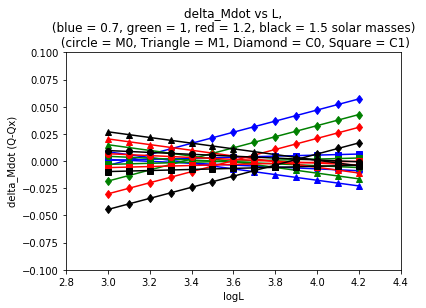

In [115]:
plot.plot(LuminosityArray,delta_log_Mdot_M0[0],color='b',marker='o')
plot.plot(LuminosityArray,delta_log_Mdot_M1[0],color='b',marker='^')
plot.plot(LuminosityArray,delta_log_Mdot_C0[0],color='b',marker='d')
plot.plot(LuminosityArray,delta_log_Mdot_C1[0],color='b',marker='s')

plot.plot(LuminosityArray,delta_log_Mdot_M0[1],color='g',marker='o')
plot.plot(LuminosityArray,delta_log_Mdot_M1[1],color='g',marker='^')
plot.plot(LuminosityArray,delta_log_Mdot_C0[1],color='g',marker='d')
plot.plot(LuminosityArray,delta_log_Mdot_C1[1],color='g',marker='s')

plot.plot(LuminosityArray,delta_log_Mdot_M0[2],color='r',marker='o')
plot.plot(LuminosityArray,delta_log_Mdot_M1[2],color='r',marker='^')
plot.plot(LuminosityArray,delta_log_Mdot_C0[2],color='r',marker='d')
plot.plot(LuminosityArray,delta_log_Mdot_C1[2],color='r',marker='s')

plot.plot(LuminosityArray,delta_log_Mdot_M0[3],color='k',marker='o')
plot.plot(LuminosityArray,delta_log_Mdot_M1[3],color='k',marker='^')
plot.plot(LuminosityArray,delta_log_Mdot_C0[3],color='k',marker='d')
plot.plot(LuminosityArray,delta_log_Mdot_C1[3],color='k',marker='s')

plot.xlabel('logL')
plot.ylabel('delta_Mdot (Q-Qx)')
plot.xlim(2.8,4.4)
plot.ylim(-0.1,0.1)
plot.title('delta_Mdot vs L,\n (blue = 0.7, green = 1, red = 1.2, black = 1.5 solar masses) \n (circle = M0, Triangle = M1, Diamond = C0, Square = C1)')